# REP paper reproduction + defender extension (Local)

This notebook uses the authors' official REP **v1.2** code. It first runs `main_short.py` as a sanity check, then the dedicated `main_fig2.py`, `main_fig3.py`, and `main_fig4.py`, redraws Figures 2–4 inline from the generated CSV files, and finally runs a defender-oriented parameter sweep.

**Important:** `main_short.py` does not itself generate Figures 2–4. The figure drivers are separate and the paper states that they can take a long time.

In [1]:

# USER CONTROLS
RUN_SHORT=True
RUN_FIG2=True
RUN_FIG3=True
RUN_FIG4=True
RUN_DEFENDER=True
DEFENDER_QUICK=True
DEFENDER_DETECTORS=['bin']
DEFENDER_SYSTEMS=['furuta_zero','furuta_hold']
DEFENDER_A_MAX=[4]
DEFENDER_WINDOWS=[10,12,14,16,18,20]
DEFENDER_P=[0.09,0.17,0.25]
DEFENDER_ALPHA=[0.005,0.01,0.05]
OMEGA_MAX=None
RESET=True


In [2]:
# SETUP: isolated author-runtime + official REP v1.2 clone
import os,sys,shutil,subprocess
from pathlib import Path

# Use current working directory for local execution
VENV=Path('repvenv')
if os.name == 'nt': # Windows
    VPY=VENV/'Scripts'/'python.exe'
    VPIP=VENV/'Scripts'/'pip.exe'
else: # Mac/Linux
    VPY=VENV/'bin'/'python'
    VPIP=VENV/'bin'/'pip'

BASE=Path('REP_base'); ROOT=Path('REP_runs')
if RESET:
    for p in [VENV,BASE,ROOT]:
        if p.exists(): shutil.rmtree(p, ignore_errors=True)
if not VENV.exists():
    subprocess.run([sys.executable,'-m','venv',str(VENV)],check=True)

subprocess.run([str(VPIP),'install','--upgrade','pip', 'setuptools', 'wheel'],check=True)
subprocess.run([str(VPIP),'install','numpy>=1.26.4','scipy>=1.12.0','gurobipy>=11.0.1'],check=True)
if not BASE.exists():
    subprocess.run(['git','clone','--branch','v1.2','--depth','1','https://github.com/Talitha-Nauta/REP.git',str(BASE)],check=True)
ROOT.mkdir(exist_ok=True)
def ws(name):
    d=ROOT/name
    if not d.exists(): shutil.copytree(BASE,d)
    return d
SHORT,FIG2,FIG3,FIG4,DEF=[ws(x) for x in ['short','fig2','fig3','fig4','defender']]
print('Author runtime:')
subprocess.run([str(VPY),'-c',"import numpy,scipy,gurobipy; print('NumPy',numpy.__version__); print('SciPy',scipy.__version__); print('Gurobi',gurobipy.gurobi.version())"],check=True)


CalledProcessError: Command '['repvenv\\Scripts\\pip.exe', 'install', '--upgrade', 'pip', 'setuptools', 'wheel']' returned non-zero exit status 1.

## Gurobi license
For local execution, if you are using a WLS license, export these as environment variables before launching Jupyter/VSCode: `GUROBI_WLSACCESSID`, `GUROBI_WLSSECRET`, `GUROBI_LICENSEID`. Otherwise, it will rely on your local `gurobi.lic` if installed globally.

In [ ]:
# Load Gurobi WLS credentials from local Environment Variables, then test solver
A=os.environ.get('GUROBI_WLSACCESSID')
S=os.environ.get('GUROBI_WLSSECRET')
L=os.environ.get('GUROBI_LICENSEID')
if A and S and L:
    lic=Path('gurobi.lic')
    lic.write_text(f'WLSACCESSID={A}\nWLSSECRET={S}\nLICENSEID={L}\n')
    os.environ['GRB_LICENSE_FILE']=str(lic.absolute())
    print('WLS license loaded from Environment Variables.')
else:
    print('No WLS environment variables loaded. Relying on default local Gurobi license.')

subprocess.run([str(VPY),'-c',"import gurobipy as gp; m=gp.Model(); x=m.addVar(lb=0); m.setObjective(x,gp.GRB.MAXIMIZE); m.addConstr(x<=1); m.optimize(); print('x=',x.X)"],env=os.environ.copy(),check=True)

def run_script(folder,script):
    print(f'\n>>> {script} in {folder}\n')
    p=subprocess.Popen([str(VPY),'-u',script],cwd=str(folder),env=os.environ.copy(),stdout=subprocess.PIPE,stderr=subprocess.STDOUT,text=True,bufsize=1)
    for line in p.stdout: print(line,end='')
    rc=p.wait(); print('\nreturn code =',rc)
    if rc: raise RuntimeError(f'{script} failed')


No WLS secrets loaded: Requesting secret GUROBI_WLSACCESSID timed out. Secrets can only be fetched when running from the Colab UI.


## 1. Run `main_short.py` first and view its result inline


>>> main_short.py in /content/REP_runs/short

starting
Execution time for sequence length  1 is:  0.017967700958251953 seconds
Execution time for sequence length  2 is:  0.011385440826416016 seconds
Execution time for sequence length  3 is:  0.011013269424438477 seconds
Execution time for sequence length  4 is:  0.015738964080810547 seconds
Execution time for sequence length  5 is:  0.0216827392578125 seconds
Execution time for sequence length  6 is:  0.03107428550720215 seconds
Execution time for sequence length  7 is:  0.07199716567993164 seconds
Execution time for sequence length  8 is:  0.09610104560852051 seconds
Execution time for sequence length  9 is:  0.14867877960205078 seconds
Execution time for sequence length  10 is:  0.239304780960083 seconds
Execution time for sequence length  11 is:  0.27080464363098145 seconds
Execution time for sequence length  12 is:  0.3672950267791748 seconds
Execution time for sequence length  13 is:  0.6286911964416504 seconds
There was a proble

,ell,attack,nominal,omega
2,1,0.000096,9.626964e-05,4.910894e-16
3,2,0.000084,7.512415e-05,9.267499e-06
4,3,0.000074,4.605331e-05,2.806196e-05
5,4,0.000057,2.234176e-05,3.476987e-05
6,5,0.000036,8.922658e-06,2.738554e-05
7,6,0.000018,3.192124e-06,1.493584e-05
8,7,0.000005,1.130592e-06,4.278653e-06
9,8,0.000012,3.665774e-07,1.170584e-05
10,9,0.000025,4.178622e-08,2.522478e-05
11,10,0.000040,6.397113e-08,4.043232e-05


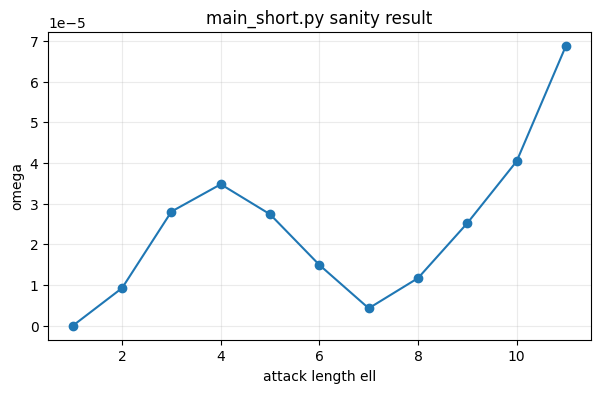

In [ ]:

if RUN_SHORT: run_script(SHORT,'main_short.py')
import pandas as pd, matplotlib.pyplot as plt
f=SHORT/'results_bin_chi2/furuta_zero/a3_p0.25_alpha0.01_w20.csv'
if f.exists():
    d=pd.read_csv(f); d.columns=[x.strip() for x in d.columns]; d['ell']=d['length']-2; d['omega']=d['attack']-d['nominal']; d=d.query('1<=ell<=25')
    display(d[['ell','attack','nominal','omega']])
    plt.figure(figsize=(7,4)); plt.plot(d.ell,d.omega,marker='o'); plt.xlabel('attack length ell'); plt.ylabel('omega'); plt.title('main_short.py sanity result'); plt.grid(alpha=.25); plt.show()


## 2. Figure 2 — effect of maximum consecutive misses


>>> main_fig2.py in /content/REP_runs/fig2

starting
Execution time for sequence length 1 is:  0.3227403163909912 seconds
Execution time for sequence length 2 is:  0.22113680839538574 seconds
Execution time for sequence length 3 is:  0.23706793785095215 seconds
Execution time for sequence length 4 is:  0.35937929153442383 seconds
Execution time for sequence length 5 is:  0.5876262187957764 seconds
Execution time for sequence length 6 is:  1.2100696563720703 seconds
Execution time for sequence length 7 is:  1.9598209857940674 seconds
Execution time for sequence length 8 is:  3.178169012069702 seconds
Execution time for sequence length 9 is:  4.8575544357299805 seconds
There was a problem for length=10, system=qt_nmp, a_max = 4, window length = 20, p miss = 0.09, test = bin + chi2
There was a problem for length=10, system=qt_nmp, a_max = 4, window length = 20, p miss = 0.17, test = bin + chi2
There was a problem for length=10, system=qt_nmp, a_max = 4, window length = 20, p miss = 0.25,

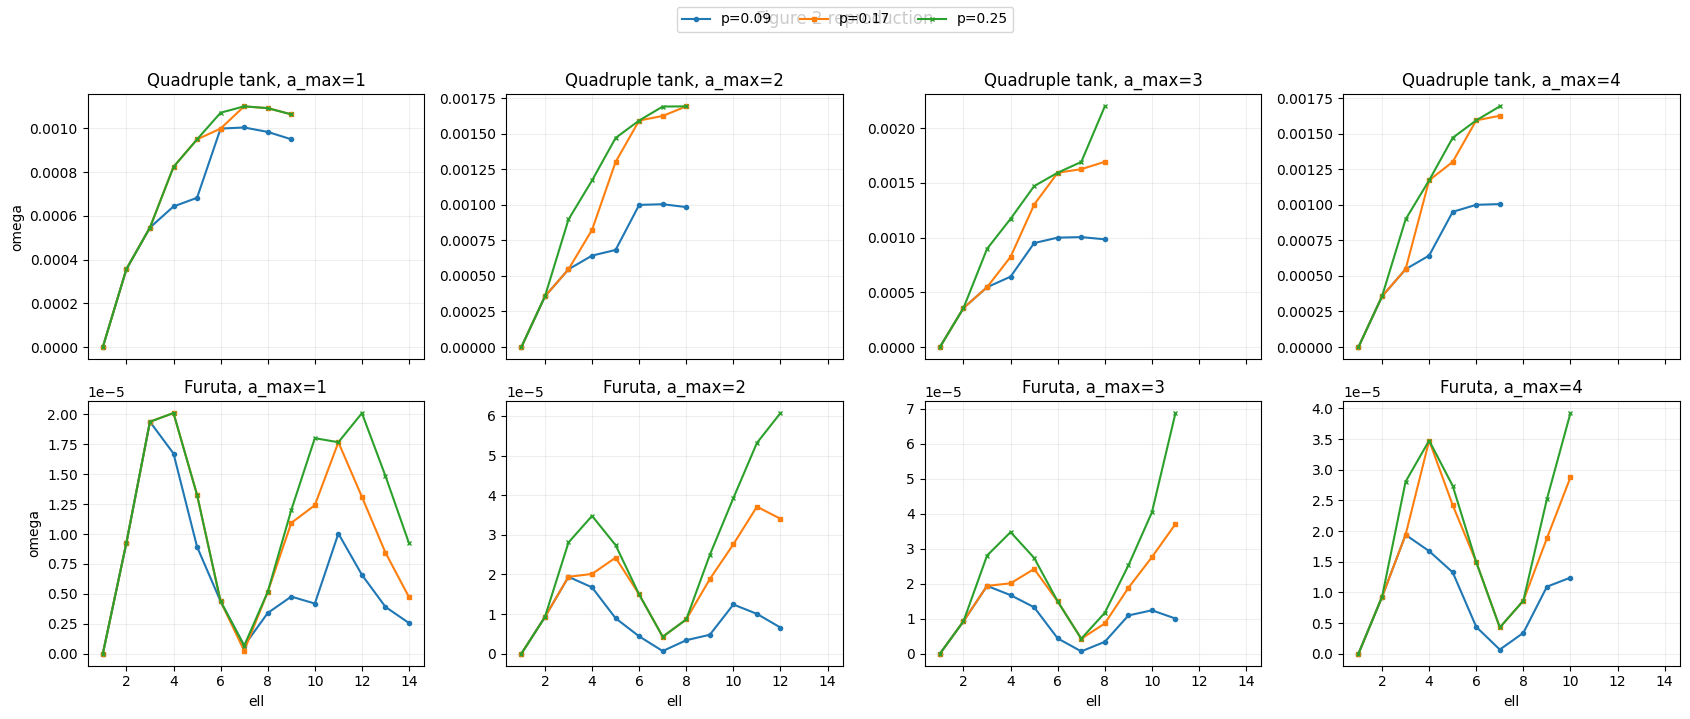

In [ ]:

if RUN_FIG2: run_script(FIG2,'main_fig2.py')
PM=[.09,.17,.25]; MK=['o','s','x']
def rd(path,tank=False):
    d=pd.read_csv(path); d.columns=[x.strip() for x in d.columns]; d['ell']=d['length']-2; d['omega']=d['attack']-d['nominal']; d=d.query('1<=ell<=25').copy()
    if tank: d['omega']/=4
    return d
def plot_fig2(root):
    fig,ax=plt.subplots(2,4,figsize=(17,7),sharex=True)
    for r,(sysn,title,tank) in enumerate([('qt_nmp','Quadruple tank',True),('furuta_zero','Furuta',False)]):
        for j,a in enumerate([1,2,3,4]):
            for p,m in zip(PM,MK):
                f=root/f'results_bin_chi2/{sysn}/a{a}_p{p}_alpha0.01_w20.csv'
                if f.exists():
                    d=rd(f,tank); ax[r,j].plot(d.ell,d.omega,marker=m,markersize=3,label=f'p={p}')
            ax[r,j].set_title(f'{title}, a_max={a}'); ax[r,j].grid(alpha=.2)
            if r==1: ax[r,j].set_xlabel('ell')
            if j==0: ax[r,j].set_ylabel('omega')
    h,l=ax[0,0].get_legend_handles_labels(); fig.legend(h,l,loc='upper center',ncol=3); fig.suptitle('Figure 2 reproduction',y=1.02); plt.tight_layout(); plt.show()
plot_fig2(FIG2)


## 3. Figure 3 — detector comparison

In [ ]:

if RUN_FIG3: run_script(FIG3,'main_fig3.py')
def plot_fig3(root):
    fig,ax=plt.subplots(3,2,figsize=(12,11),sharex=True)
    rows=[('results_bin','Binomial'),('results_bin_chi2','Combined'),('results_chi2','Geometric / chi2')]
    cols=[('qt_nmp','Quadruple tank',True),('furuta_zero','Furuta',False)]
    for r,(folder,dname) in enumerate(rows):
        for j,(sysn,sname,tank) in enumerate(cols):
            for p,m in zip(PM,MK):
                f=root/f'{folder}/{sysn}/a4_p{p}_alpha0.01_w20.csv'
                if f.exists():
                    d=rd(f,tank); ax[r,j].plot(d.ell,d.omega,marker=m,markersize=3,label=f'p={p}')
            ax[r,j].set_title(f'{dname} — {sname}'); ax[r,j].grid(alpha=.2)
            if r==2: ax[r,j].set_xlabel('ell')
            if j==0: ax[r,j].set_ylabel('omega')
    h,l=ax[0,0].get_legend_handles_labels(); fig.legend(h,l,loc='upper center',ncol=3); fig.suptitle('Figure 3 reproduction',y=1.02); plt.tight_layout(); plt.show()
plot_fig3(FIG3)


## 4. Figure 4 — zero vs hold and window length


>>> main_fig4.py in /content/REP_runs/fig4

starting
Execution time for sequence length 1 is:  0.09818887710571289 seconds
Execution time for sequence length 2 is:  0.150665283203125 seconds
Execution time for sequence length 3 is:  0.21915555000305176 seconds
Execution time for sequence length 4 is:  0.3240532875061035 seconds
Execution time for sequence length 5 is:  0.46099090576171875 seconds
Execution time for sequence length 6 is:  0.9043903350830078 seconds
Execution time for sequence length 7 is:  1.2546188831329346 seconds
Execution time for sequence length 8 is:  1.8753581047058105 seconds
Execution time for sequence length 9 is:  2.507030725479126 seconds
Execution time for sequence length 10 is:  3.7383828163146973 seconds
Execution time for sequence length 11 is:  5.336813688278198 seconds
Execution time for sequence length 12 is:  8.10664987564087 seconds
Execution time for sequence length 13 is:  11.899816751480103 seconds
Execution time for sequence length 14 is:  19.0

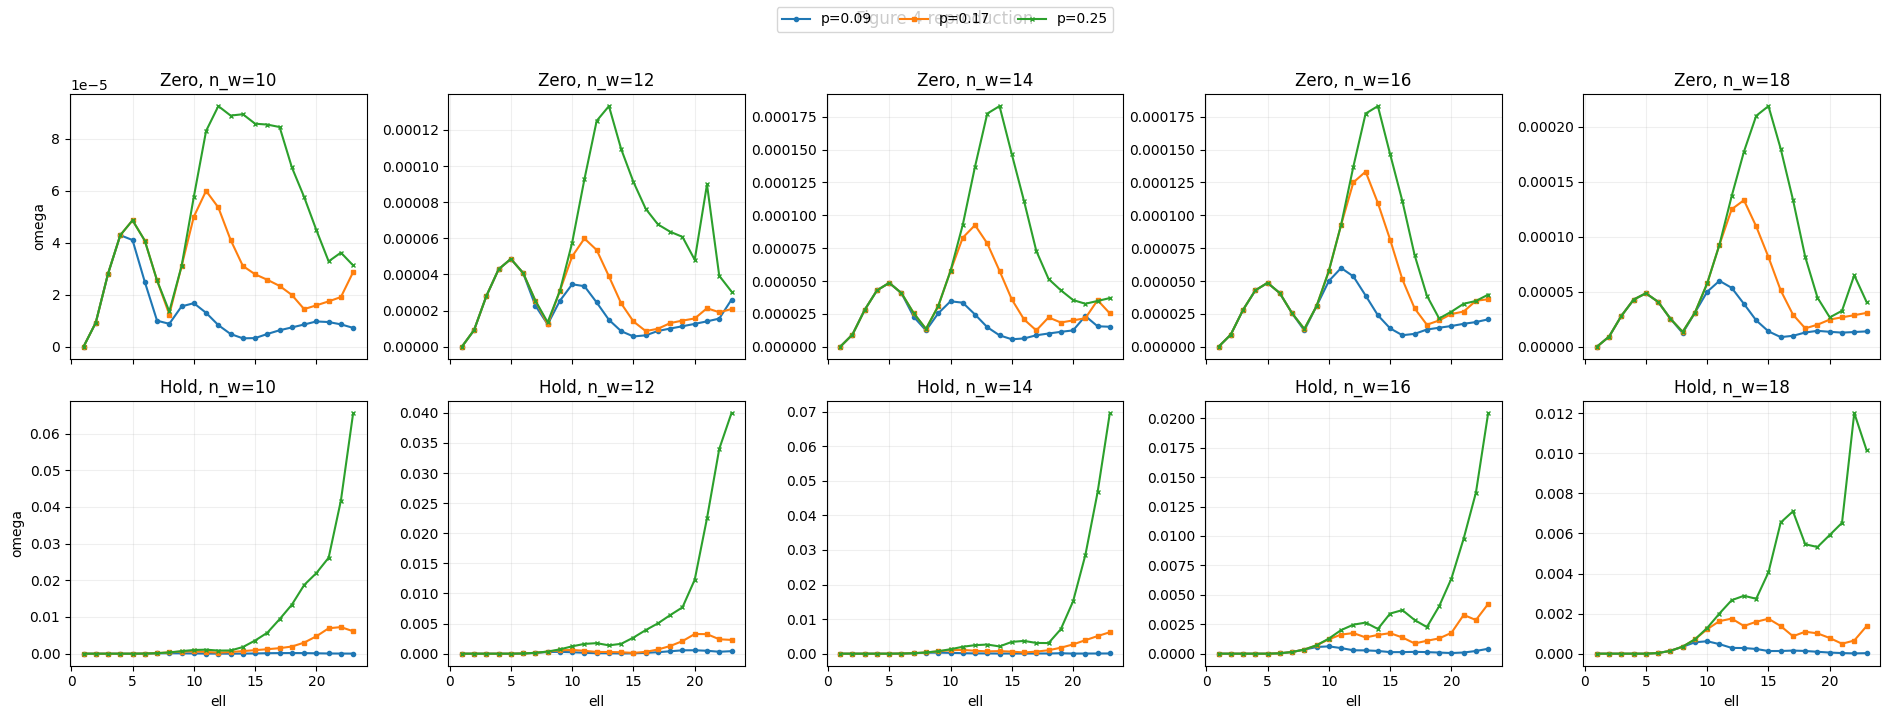

In [ ]:

if RUN_FIG4: run_script(FIG4,'main_fig4.py')
def plot_fig4(root):
    fig,ax=plt.subplots(2,5,figsize=(19,7),sharex=True)
    for r,(sysn,policy) in enumerate([('furuta_zero','Zero'),('furuta_hold','Hold')]):
        for j,w in enumerate([10,12,14,16,18]):
            for p,m in zip(PM,MK):
                f=root/f'results_bin/{sysn}/a4_p{p}_alpha0.01_w{w}.csv'
                if f.exists():
                    d=rd(f); ax[r,j].plot(d.ell,d.omega,marker=m,markersize=3,label=f'p={p}')
            ax[r,j].set_title(f'{policy}, n_w={w}'); ax[r,j].grid(alpha=.2)
            if r==1: ax[r,j].set_xlabel('ell')
            if j==0: ax[r,j].set_ylabel('omega')
    h,l=ax[0,0].get_legend_handles_labels(); fig.legend(h,l,loc='upper center',ncol=3); fig.suptitle('Figure 4 reproduction',y=1.02); plt.tight_layout(); plt.show()
plot_fig4(FIG4)



## 5. Defender extension
This preserves the exact `define_system()` block from `main_short.py` and executes the authors' original optimization files. The extension changes only the outer experiment sweep. By default it focuses on the Figure-4 weakness (binomial detector, zero vs hold, several `n_w`, `p_miss`, and `alpha` values).


In [ ]:

# Generate a new driver from the top of main_short.py
src=(DEF/'main_short.py').read_text(); marker='#Create output folders'
if marker not in src: raise RuntimeError('main_short.py marker not found')
prefix=src.split(marker)[0]
ells=[5,10,15,20,25] if DEFENDER_QUICK else list(range(1,26))
extension=f"""
import csv,shutil,traceback
from pathlib import Path
OUT=Path('defender_results')
DETECTORS={DEFENDER_DETECTORS!r}; SYSTEMS={DEFENDER_SYSTEMS!r}; AMAX={DEFENDER_A_MAX!r}; WINDOWS={DEFENDER_WINDOWS!r}; PVALS={DEFENDER_P!r}; ALPHAS={DEFENDER_ALPHA!r}; ELLS={ells!r}
OPT={{'bin':Path('optimise_bin.py'),'bin_chi2':Path('optimise_bin_chi2.py'),'chi2':Path('optimise_chi2.py')}}
if {RESET!r} and OUT.exists(): shutil.rmtree(OUT)
for det in DETECTORS:
    for sysn in SYSTEMS: (OUT/f'results_{{det}}'/sysn).mkdir(parents=True,exist_ok=True)
def hasrow(path,n):
    if not path.exists(): return False
    try:
        for r in csv.DictReader(open(path)):
            try:
                if int(r['length'].strip())==n: return True
            except: pass
    except: pass
    return False
base=Path.cwd(); done=skip=fail=0
for det in DETECTORS:
    opt=(base/OPT[det]).resolve()
    for system in SYSTEMS:
        Phi_miss,Phi_hit,C,Q,x0,nx=define_system(system)
        for a_max in AMAX:
            for significance_level in ALPHAS:
                ws=[20] if det=='chi2' else WINDOWS
                for window_length in ws:
                    for p_miss in PVALS:
                        for ell in ELLS:
                            a_length=ell+2
                            csvp=base/OUT/f'results_{{det}}'/system/f'a{{a_max}}_p{{p_miss}}_alpha{{significance_level}}_w{{window_length}}.csv'
                            if hasrow(csvp,a_length): skip+=1; continue
                            print(f'SOLVE {{det}} {{system}} a={{a_max}} alpha={{significance_level}} w={{window_length}} p={{p_miss}} ell={{ell}}',flush=True)
                            try:
                                os.chdir(base/OUT); exec(compile(opt.read_text(),str(opt),'exec'),globals()); done+=1
                            except Exception as e:
                                print('FAILED',repr(e)); traceback.print_exc(); fail+=1
                            finally: os.chdir(base)
print('completed',done,'skipped',skip,'failed',fail)
"""
(DEF/'main_defender.py').write_text(prefix+extension)
print('Generated',DEF/'main_defender.py','with ell=',ells)
if RUN_DEFENDER: run_script(DEF,'main_defender.py')


Generated /content/REP_runs/defender/main_defender.py with ell= [5, 10, 15, 20, 25]

>>> main_defender.py in /content/REP_runs/defender

SOLVE bin furuta_zero a=4 alpha=0.005 w=10 p=0.09 ell=5
SOLVE bin furuta_zero a=4 alpha=0.005 w=10 p=0.09 ell=10
SOLVE bin furuta_zero a=4 alpha=0.005 w=10 p=0.09 ell=15
SOLVE bin furuta_zero a=4 alpha=0.005 w=10 p=0.09 ell=20
SOLVE bin furuta_zero a=4 alpha=0.005 w=10 p=0.09 ell=25
FAILED GurobiError(10010, 'Model too large for size-limited license; visit https://gurobi.com/unrestricted for more information')
Traceback (most recent call last):
  File "/content/REP_runs/defender/main_defender.py", line 86, in <module>
    os.chdir(base/OUT); exec(compile(opt.read_text(),str(opt),'exec'),globals()); done+=1
                        ~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/content/REP_runs/defender/optimise_bin.py", line 71, in <module>
    m.optimize()
    ~~~~~~~~~~^^
  File "src/gurobipy/_model.pyx", line 926, in gurobipy._mod

BEST configurations


,detector,policy,a_max,alpha,window_length,p_miss,worst_ell,worst_omega
0,bin,zero,4,0.050,14,0.09,5,0.000041
1,bin,zero,4,0.050,10,0.09,5,0.000041
2,bin,zero,4,0.050,12,0.09,5,0.000041
3,bin,zero,4,0.050,16,0.09,5,0.000041
4,bin,zero,4,0.010,10,0.09,5,0.000041
5,bin,zero,4,0.005,10,0.09,5,0.000049
6,bin,zero,4,0.050,10,0.17,5,0.000049
7,bin,zero,4,0.005,12,0.09,5,0.000049
8,bin,zero,4,0.010,12,0.09,5,0.000049
9,bin,zero,4,0.050,12,0.17,5,0.000049


WORST configurations


,detector,policy,a_max,alpha,window_length,p_miss,worst_ell,worst_omega
106,bin,hold,4,0.005,10,0.25,20,0.021973
107,bin,hold,4,0.010,10,0.25,20,0.021973
104,bin,hold,4,0.010,14,0.25,20,0.015138
105,bin,hold,4,0.005,14,0.25,20,0.015138
103,bin,hold,4,0.005,16,0.25,20,0.013555
101,bin,hold,4,0.010,12,0.25,20,0.012288
102,bin,hold,4,0.005,12,0.25,20,0.012288
100,bin,hold,4,0.005,18,0.25,20,0.012185
99,bin,hold,4,0.005,20,0.25,20,0.011962
98,bin,hold,4,0.010,20,0.25,20,0.011962


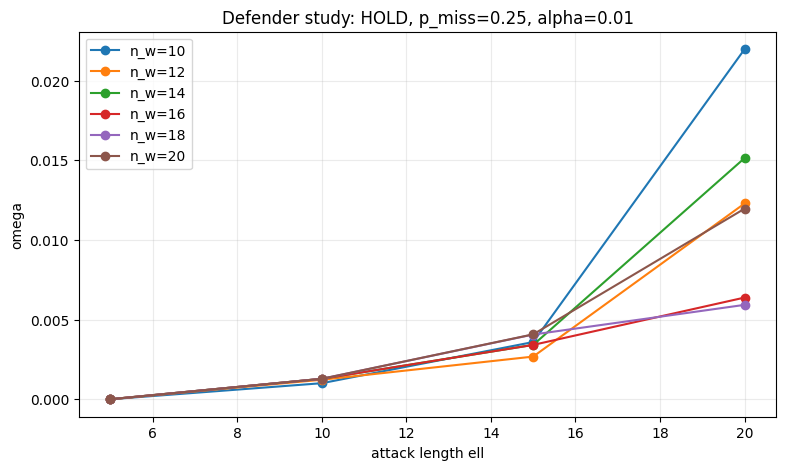

window_length,10,12,14,16,18,20
p_miss,,,,,,
0.09,0.000107,0.000569,0.000240,0.000621,0.000621,0.000621
0.17,0.004749,0.003263,0.002684,0.001769,0.001744,0.003410
0.25,0.021973,0.012288,0.015138,0.006382,0.005924,0.011962


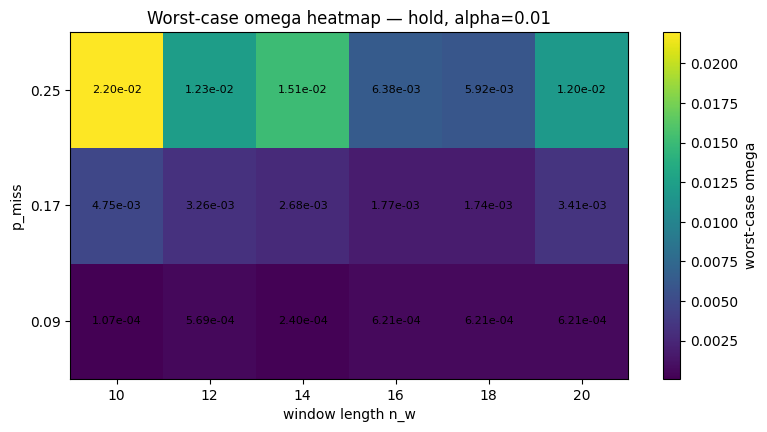

In [ ]:

# Read defender outputs, rank by worst-case omega, and show inline plots
import re, pandas as pd, matplotlib.pyplot as plt
R=DEF/'defender_results'; pat=re.compile(r'a(?P<a>\d+)_p(?P<p>[0-9.]+)_alpha(?P<al>[0-9.]+)_w(?P<w>\d+)\.csv'); rows=[]
for det in DEFENDER_DETECTORS:
    for sysn in DEFENDER_SYSTEMS:
        folder=R/f'results_{det}'/sysn
        if not folder.exists(): continue
        for f in folder.glob('*.csv'):
            m=pat.match(f.name)
            if not m: continue
            d=pd.read_csv(f); d.columns=[x.strip() for x in d.columns]
            for _,r in d.iterrows():
                ell=int(r['length'])-2
                if 1<=ell<=25:
                    rows.append(dict(detector=det,policy='zero' if sysn=='furuta_zero' else 'hold',a_max=int(m['a']),alpha=float(m['al']),window_length=int(m['w']),p_miss=float(m['p']),ell=ell,omega=float(r['attack'])-float(r['nominal'])))
points=pd.DataFrame(rows)
if points.empty:
    print('No defender results found.')
else:
    keys=['detector','policy','a_max','alpha','window_length','p_miss']
    ix=points.groupby(keys)['omega'].idxmax(); summary=points.loc[ix,keys+['ell','omega']].rename(columns={'ell':'worst_ell','omega':'worst_omega'}).sort_values('worst_omega').reset_index(drop=True)
    if OMEGA_MAX is not None: summary['classification']=summary.worst_omega.map(lambda x:'SAFE' if x<=OMEGA_MAX else 'UNSAFE')
    print('BEST configurations'); display(summary.head(15)); print('WORST configurations'); display(summary.tail(15).sort_values('worst_omega',ascending=False))
    points.to_csv(R/'defender_all_points.csv',index=False); summary.to_csv(R/'defender_worst_case_summary.csv',index=False)
    det=DEFENDER_DETECTORS[0]; q=points.query("detector==@det and policy=='hold' and p_miss==0.25 and alpha==0.01")
    plt.figure(figsize=(9,5))
    for w in sorted(q.window_length.unique()):
        d=q[q.window_length==w].sort_values('ell'); plt.plot(d.ell,d.omega,marker='o',label=f'n_w={w}')
    if OMEGA_MAX is not None: plt.axhline(OMEGA_MAX,ls='--',label='safety bound')
    plt.xlabel('attack length ell'); plt.ylabel('omega'); plt.title('Defender study: HOLD, p_miss=0.25, alpha=0.01'); plt.grid(alpha=.25); plt.legend(); plt.show()
    h=summary.query("detector==@det and policy=='hold' and alpha==0.01")
    pv=h.pivot(index='p_miss',columns='window_length',values='worst_omega'); display(pv)
    plt.figure(figsize=(9,4.5)); im=plt.imshow(pv.values,aspect='auto',origin='lower'); plt.colorbar(im,label='worst-case omega'); plt.xticks(range(len(pv.columns)),pv.columns); plt.yticks(range(len(pv.index)),[f'{x:.2f}' for x in pv.index]); plt.xlabel('window length n_w'); plt.ylabel('p_miss'); plt.title('Worst-case omega heatmap — hold, alpha=0.01')
    for i in range(len(pv.index)):
        for j in range(len(pv.columns)):
            v=pv.iloc[i,j]
            if pd.notna(v): plt.text(j,i,f'{v:.2e}',ha='center',va='center',fontsize=8)
    plt.show()



## Next extension
After this works, set `DEFENDER_QUICK=False`, add `bin_chi2`, sweep `a_max=[1,2,3,4]`, and then add an actual Furuta state/angle safety bound. The files `defender_all_points.csv` and `defender_worst_case_summary.csv` are saved under the defender workspace.
